# Reto avanzado 1 · Comparativa de algoritmos de clustering

**Malackathon 2026 · Mercedes-Benz · "Clustering the Star"**

Objetivo: comprobar si K-Means es el algoritmo más adecuado para segmentar a los clientes, comparándolo con otros algoritmos de clustering
entrenados con **el mismo número de grupos (k = 6)** y **los mismos datos preparados**. Este notebook cubre:

1. Datos y criterios de comparación
2. K-Means (referencia)
3. Gaussian Mixture Models
4. Agglomerative Clustering
5. DBSCAN (contraste)
6. Tabla y gráfico comparativo de métricas
7. ¿Cambian los segmentos entre algoritmos?
8. Conclusión

## 1. Datos y criterios de comparación

Usamos la misma matriz con la que se entrenó K-Means en el cuaderno 03 (`X_model_fe2.pkl`): 173.456 clientes y 18 columnas ya codificadas
y escaladas. Así cualquier diferencia entre algoritmos se debe al algoritmo y no a los datos.

Comparamos los algoritmos con cuatro tipos de criterios:

| Criterio | Qué mide | Mejor cuanto… |
|---|---|---|
| **Silueta** | Si cada cliente está más cerca de su grupo que del grupo vecino | más alta |
| **Davies-Bouldin** | Cuánto se parece cada grupo a su grupo más similar | más baja |
| **Calinski-Harabasz** | Separación entre grupos frente a dispersión dentro de ellos | más alta |
| **Tamaño del grupo menor y mayor** | Si los segmentos son equilibrados y utilizables para marketing | grupos ni diminutos ni gigantes |

Para que la comparación sea justa, la silueta de **todos** los algoritmos se calcula sobre **las mismas 3 muestras de 20.000 clientes**
(calcularla con todos sería demasiado costoso) y se promedia. Davies-Bouldin y Calinski-Harabasz se calculan con todos los clientes.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import time
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

df_prepared = pd.read_pickle(DATA_DIR / "X_model_fe2.pkl")
X = df_prepared.values
K = 6
rng = np.random.default_rng(42)
MUESTRAS_SIL = [rng.choice(len(X), 20_000, replace=False) for _ in range(3)]
print(f"{X.shape[0]:,} clientes · {X.shape[1]} columnas · k = {K}")

def evaluar(nombre, etiquetas, segundos, notas=""):
    """Calcula las métricas de una segmentación sobre todos los clientes (silueta: media de las 3 muestras comunes)."""
    tam = np.bincount(etiquetas, minlength=K) / len(etiquetas) * 100
    return {
        "algoritmo": nombre,
        "silueta": np.mean([silhouette_score(X[m], etiquetas[m]) for m in MUESTRAS_SIL]),
        "davies_bouldin": davies_bouldin_score(X, etiquetas),
        "calinski_harabasz": calinski_harabasz_score(X, etiquetas),
        "grupo_menor_%": tam.min(),
        "grupo_mayor_%": tam.max(),
        "segundos": segundos,
        "notas": notas,
    }

resultados, etiquetas = [], {}

173,456 clientes · 18 columnas · k = 6


## 2. K-Means (referencia)

Entrenamos K-Means exactamente igual que en el cuaderno 03 (`n_init=10`, `random_state=42`). K-Means asigna cada cliente al centro más
cercano y recoloca los centros hasta que no cambian: busca grupos **compactos y de forma aproximadamente esférica**.

In [2]:
t0 = time.time()
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
etiquetas["K-Means"] = kmeans.labels_
resultados.append(evaluar("K-Means", kmeans.labels_, time.time() - t0, "Modelo elegido en el cuaderno 03"))

# Comprobación: son los mismos clústeres que guardó el cuaderno 03
fichero_03 = DATA_DIR / "clientes_clusters.csv"
if fichero_03.exists():
    guardados = pd.read_csv(fichero_03, usecols=["cluster"])["cluster"].to_numpy()
    print("Mismos clústeres que el cuaderno 03:", bool((guardados == kmeans.labels_).all()))
pd.DataFrame(resultados).round(3)

Mismos clústeres que el cuaderno 03: True


,algoritmo,silueta,davies_bouldin,calinski_harabasz,grupo_menor_%,grupo_mayor_%,segundos,notas
0,K-Means,0.11,1.963,16976.149,12.401,19.327,2.7,Modelo elegido en el cuaderno 03


## 3. Gaussian Mixture Models (GMM)

Un GMM supone que los clientes proceden de una mezcla de 6 distribuciones normales (gaussianas) y estima, para cada cliente, la **probabilidad**
de pertenecer a cada una. A diferencia de K-Means, admite grupos alargados o de distinto tamaño, porque cada gaussiana tiene su propia covarianza.

Probamos los dos tipos de covarianza más habituales:
- **`full`**: cada grupo puede tener cualquier forma (el más flexible).
- **`diag`**: cada grupo tiene sus propias varianzas, pero sin correlaciones entre variables (más simple).

Usamos `n_init=3` (tres arranques distintos, nos quedamos con el mejor) y `random_state=42` para que sea reproducible.

In [3]:
modelos_gmm = {}
for cov in ["full", "diag"]:
    t0 = time.time()
    gmm = GaussianMixture(n_components=K, covariance_type=cov, n_init=3, max_iter=300, random_state=42).fit(X)
    seg = time.time() - t0
    etiquetas[f"GMM ({cov})"] = gmm.predict(X)
    modelos_gmm[cov] = gmm
    confianza = gmm.predict_proba(X).max(axis=1)
    resultados.append(evaluar(f"GMM ({cov})", etiquetas[f"GMM ({cov})"], seg,
                              f"Probabilidad media del grupo asignado: {confianza.mean():.3f}"))
pd.DataFrame(resultados).round(3)

,algoritmo,silueta,davies_bouldin,calinski_harabasz,grupo_menor_%,grupo_mayor_%,segundos,notas
0,K-Means,0.110,1.963,16976.149,12.401,19.327,2.700,Modelo elegido en el cuaderno 03
1,GMM (full),0.086,3.067,8758.655,3.255,45.392,8.967,Probabilidad media del grupo asignado: 1.000
2,GMM (diag),0.096,2.691,8529.690,2.145,45.392,2.780,Probabilidad media del grupo asignado: 1.000


El GMM obtiene peor silueta que K-Means, un grupo que concentra casi la mitad de los clientes y, llamativamente, una probabilidad media de
pertenencia prácticamente igual a 1: el modelo está "seguro" de todos los clientes. Para entender por qué, miramos qué tienen en común los
clientes de cada componente en las columnas binarias (0/1) de financiación y motorización:

In [4]:
binarias = [c for c in df_prepared.columns if df_prepared[c].isin([0, 1]).all()]
composicion = df_prepared[binarias].groupby(etiquetas["GMM (full)"]).mean()
composicion.columns = [c.replace("finance_leasing_status_", "financ_").replace("main_engine_concept_", "motor_") for c in composicion.columns]
composicion.insert(0, "% clientes", pd.Series(etiquetas["GMM (full)"]).value_counts(normalize=True).sort_index().values * 100)
composicion.index.name = "componente GMM"
composicion.round(2)

,% clientes,main_is_van,has_telemetry,financ_active_FL_and_CASH,financ_active_FL_only,financ_never_active,financ_was_active,motor_COMBUSTION,motor_ELECTRIC,motor_MILD_HYBRID,motor_PLUGIN_HYBRID,motor_UNKNOWN
componente GMM,,,,,,,,,,,,
0,17.32,0.16,0.65,0.14,0.86,0.0,0.0,0.60,0.03,0.33,0.02,0.02
1,45.39,0.17,0.58,0.00,0.00,1.0,0.0,0.85,0.00,0.00,0.00,0.15
2,11.67,0.00,0.59,0.00,0.00,1.0,0.0,0.00,0.00,1.00,0.00,0.00
3,13.51,0.00,0.61,0.00,0.00,1.0,0.0,0.00,0.45,0.00,0.55,0.00
4,8.86,0.00,0.62,0.00,1.00,0.0,0.0,0.00,0.38,0.00,0.38,0.24
5,3.26,0.11,0.57,0.00,0.00,0.0,1.0,0.50,0.12,0.18,0.11,0.10


**Diagnóstico.** Cada componente del GMM está definido casi por completo por las columnas 0/1. Todas reúnen a clientes con **la misma
situación de financiación**: o ninguno ha financiado nunca, o todos tienen financiación activa, o todos la tuvieron en el pasado (por ejemplo,
la componente que concentra casi la mitad de los clientes son exactamente los que nunca han financiado). Varias son "puras" también en
motorización: una contiene solo mild-hybrid y otra solo eléctricos e híbridos enchufables.

La razón es matemática: el GMM supone datos **continuos y gaussianos**. Cuando un grupo tiene una columna 0/1 constante, su varianza en esa
columna es cero, la densidad gaussiana se vuelve enorme y al modelo le "compensa" separar a los clientes por esas columnas en lugar de por su
perfil completo. Por eso las probabilidades salen todas cercanas a 1. Es decir, **el GMM no es adecuado para datos con muchas variables
categóricas codificadas en one-hot** como los nuestros.

## 4. Agglomerative Clustering

El clustering jerárquico aglomerativo empieza con cada cliente como un grupo y va **uniendo los dos grupos más parecidos** hasta quedarse con 6.
Probamos dos criterios de unión:
- **`ward`**: une los grupos que menos aumentan la dispersión interna (el criterio más parecido a K-Means).
- **`average`**: une los grupos con menor distancia media entre sus clientes.

**Limitación de escala.** El algoritmo necesita la distancia entre todos los pares de clientes: con 173.456 serían unos 15.000 millones de
distancias (más de 100 GB de memoria). Por eso lo entrenamos con una **muestra aleatoria de 15.000 clientes** y después asignamos cada uno del
resto al grupo de su **cliente más parecido** de la muestra (vecino más cercano).

Para comprobar que la comparación es justa, entrenamos también **K-Means con la misma muestra y la misma extensión**: si ese K-Means sigue
siendo mejor que el aglomerativo, la diferencia se debe al algoritmo y no al uso de una muestra.

In [5]:
MUESTRA_AGG = rng.choice(len(X), 15_000, replace=False)

def entrenar_en_muestra_y_extender(modelo):
    """Entrena con la muestra y asigna el resto de clientes al grupo de su vecino más cercano en la muestra."""
    etiquetas_muestra = modelo.fit_predict(X[MUESTRA_AGG])
    vecino = KNeighborsClassifier(n_neighbors=1).fit(X[MUESTRA_AGG], etiquetas_muestra)
    return vecino.predict(X)

for nombre, modelo, nota in [
    ("Agglomerative (ward)", AgglomerativeClustering(n_clusters=K, linkage="ward"), "Muestra de 15.000 + vecino más cercano"),
    ("Agglomerative (average)", AgglomerativeClustering(n_clusters=K, linkage="average"), "Muestra de 15.000 + vecino más cercano"),
    ("K-Means (misma muestra)", KMeans(n_clusters=K, n_init=10, random_state=42), "Control: K-Means con la misma muestra que el aglomerativo"),
]:
    t0 = time.time()
    etiquetas[nombre] = entrenar_en_muestra_y_extender(modelo)
    resultados.append(evaluar(nombre, etiquetas[nombre], time.time() - t0, nota))
pd.DataFrame(resultados).round(3)

,algoritmo,silueta,davies_bouldin,calinski_harabasz,grupo_menor_%,grupo_mayor_%,segundos,notas
0,K-Means,0.110,1.963,16976.149,12.401,19.327,2.700,Modelo elegido en el cuaderno 03
1,GMM (full),0.086,3.067,8758.655,3.255,45.392,8.967,Probabilidad media del grupo asignado: 1.000
2,GMM (diag),0.096,2.691,8529.690,2.145,45.392,2.780,Probabilidad media del grupo asignado: 1.000
3,Agglomerative (ward),0.075,2.679,10409.103,9.001,28.004,6.929,Muestra de 15.000 + vecino más cercano
4,Agglomerative (average),0.052,1.833,1063.209,0.002,96.952,7.860,Muestra de 15.000 + vecino más cercano
5,K-Means (misma muestra),0.102,2.007,16227.073,12.570,18.967,1.865,Control: K-Means con la misma muestra que el a...


- **`average`** degenera: casi todos los clientes acaban en un único grupo y los otros cinco son diminutos. Al unir por distancia media, los
  clientes "raros" (con valores extremos) forman grupos de muy pocas personas y el resto queda junto. No sirve para segmentar.
- **`ward`** produce grupos utilizables, aunque menos equilibrados que K-Means (entre el 9 % y el 28 % de los clientes), y con una silueta
  claramente inferior.
- El **control** (K-Means con la misma muestra) mantiene una silueta parecida a la del K-Means completo y superior a la de Ward: la peor silueta
  del aglomerativo se debe al algoritmo, no a haber usado una muestra.

## 5. DBSCAN (contraste)

DBSCAN agrupa a los clientes que están en **zonas densas** y marca como **ruido** a los que quedan aislados. A diferencia del resto, **no se le
puede indicar k = 6**: el número de grupos lo decide él según dos parámetros, el radio de vecindad (`eps`) y el mínimo de vecinos para formar
un grupo (`min_samples`). Por eso no cumple la condición de "mismo k" y lo incluimos solo como contraste.

Para elegir `eps` de forma razonada usamos el **gráfico de k-distancias**: para cada cliente, la distancia a su vecino número `min_samples`,
ordenada. El "codo" de esa curva indica el radio a partir del cual los puntos dejan de estar en zonas densas. Usamos `min_samples = 36`
(el doble del número de columnas, una regla habitual) y una muestra de 20.000 clientes por coste de cálculo.

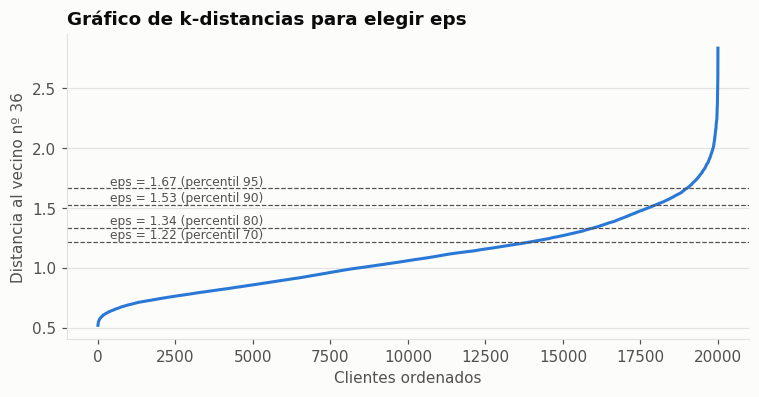

,eps,percentil,nº de grupos,% ruido,% en el grupo mayor
0,1.22,70,13,9.8,38.5
1,1.34,80,12,6.2,38.7
2,1.53,90,1,1.6,98.4
3,1.67,95,1,0.5,99.5


In [6]:
MIN_SAMPLES = 2 * X.shape[1]
D = X[MUESTRAS_SIL[0]]
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(D).kneighbors(D)[0][:, -1])
percentiles = [70, 80, 90, 95]
eps_candidatos = np.percentile(kdist, percentiles)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(kdist, color=ps.SERIES[0], lw=2)
for p, e in zip(percentiles, eps_candidatos):
    ax.axhline(e, color=ps.INK_2, ls="--", lw=0.8)
    ax.text(len(kdist) * 0.02, e, f"eps = {e:.2f} (percentil {p})", va="bottom", fontsize=8, color=ps.INK_2)
ax.set_xlabel("Clientes ordenados"); ax.set_ylabel(f"Distancia al vecino nº {MIN_SAMPLES}")
ax.set_title("Gráfico de k-distancias para elegir eps")
fig.savefig(FIG_DIR / "A1_kdistancias.png"); plt.show()

filas = []
for p, e in zip(percentiles, eps_candidatos):
    l = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(D)
    grupos = pd.Series(l[l >= 0]).value_counts(normalize=True)
    filas.append({"eps": round(e, 2), "percentil": p, "nº de grupos": int(l.max() + 1),
                  "% ruido": round((l == -1).mean() * 100, 1),
                  "% en el grupo mayor": round((l == pd.Series(l[l >= 0]).mode()[0]).mean() * 100, 1) if (l >= 0).any() else 0})
pd.DataFrame(filas)

Ninguna configuración produce 6 segmentos útiles: con radios pequeños aparecen muchos grupos y bastante ruido, y en cuanto el radio crece un poco
casi todos los clientes se funden en **un único grupo**. Es lo esperable en una base de clientes que, como vimos en el cuaderno 03 y en el PCA,
forma un **continuo** sin zonas densas separadas por huecos: DBSCAN no encuentra fronteras naturales. Además, dejaría a una parte de los
clientes como "ruido" sin segmento, algo poco práctico para marketing. **DBSCAN queda descartado** para este problema.

## 6. Tabla y gráfico comparativo de métricas

In [7]:
tabla = pd.DataFrame(resultados).set_index("algoritmo")
tabla_vis = tabla.drop(columns="notas").round({"silueta": 3, "davies_bouldin": 3, "calinski_harabasz": 0,
                                                 "grupo_menor_%": 1, "grupo_mayor_%": 1, "segundos": 1})
tabla.to_csv(ROOT / "reports" / "A1_comparativa_algoritmos.csv")
tabla_vis

,silueta,davies_bouldin,calinski_harabasz,grupo_menor_%,grupo_mayor_%,segundos
algoritmo,,,,,,
K-Means,0.110,1.963,16976.0,12.4,19.3,2.7
GMM (full),0.086,3.067,8759.0,3.3,45.4,9.0
GMM (diag),0.096,2.691,8530.0,2.1,45.4,2.8
Agglomerative (ward),0.075,2.679,10409.0,9.0,28.0,6.9
Agglomerative (average),0.052,1.833,1063.0,0.0,97.0,7.9
K-Means (misma muestra),0.102,2.007,16227.0,12.6,19.0,1.9


K-Means obtiene la mejor silueta y el mejor Calinski-Harabasz. En Davies-Bouldin el valor más bajo es el de Agglomerative con `average`, pero
corresponde a una segmentación degenerada (97 % de los clientes en un grupo): el índice se ve favorecido porque los cinco grupos restantes son
unos pocos clientes extremos muy alejados del resto. Por eso las métricas siempre deben leerse junto al tamaño de los grupos.

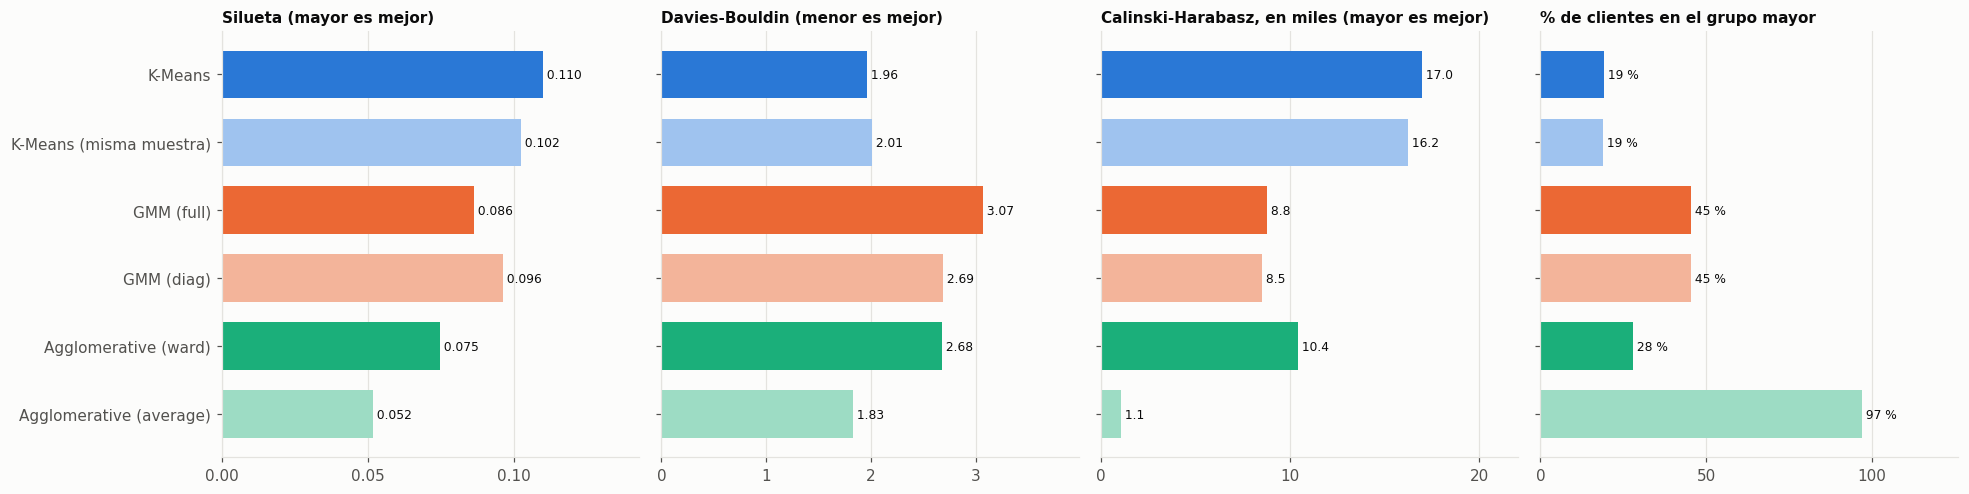

In [8]:
ORDEN = ["K-Means", "K-Means (misma muestra)", "GMM (full)", "GMM (diag)", "Agglomerative (ward)", "Agglomerative (average)"]
t = tabla.loc[ORDEN]
colores = [ps.SERIES[0], "#9fc3ef", ps.SERIES[1], "#f3b49a", ps.SERIES[2], "#9ddcc4"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
paneles = [("silueta", "Silueta (mayor es mejor)", "{:.3f}"),
           ("davies_bouldin", "Davies-Bouldin (menor es mejor)", "{:.2f}"),
           ("calinski_harabasz", "Calinski-Harabasz, en miles (mayor es mejor)", "{:,.1f}"),
           ("grupo_mayor_%", "% de clientes en el grupo mayor", "{:.0f} %")]
for ax, (col, titulo, fmt) in zip(axes, paneles):
    valores = t[col] / 1000 if col == "calinski_harabasz" else t[col]
    bars = ax.barh(range(len(t)), valores, color=colores, height=0.7)
    for b, v in zip(bars, valores):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, " " + fmt.format(v), va="center", fontsize=8, color=ps.INK)
    ax.set_yticks(range(len(t)), t.index if ax is axes[0] else [""] * len(t))
    ax.invert_yaxis(); ax.set_title(titulo, fontsize=10); ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_axisbelow(True)
    ax.set_xlim(0, valores.max() * 1.3); ax.locator_params(axis="x", nbins=4)
fig.tight_layout(); fig.savefig(FIG_DIR / "A1_comparativa_metricas.png"); plt.show()

## 7. ¿Cambian los segmentos entre algoritmos?

Para saber si los algoritmos encuentran **los mismos segmentos** (aunque los numeren distinto) usamos dos medidas de coincidencia entre
segmentaciones, que no dependen de la numeración de los grupos:

- **ARI (Adjusted Rand Index)**: 1 si las dos segmentaciones son idénticas y 0 si coinciden lo mismo que si fueran al azar.
- **NMI (Normalized Mutual Information)**: de 0 a 1, cuánta información comparten las dos segmentaciones.

In [9]:
ref = etiquetas["K-Means"]
coincidencia = pd.DataFrame({
    "ARI frente a K-Means": {n: adjusted_rand_score(ref, l) for n, l in etiquetas.items() if n != "K-Means"},
    "NMI frente a K-Means": {n: normalized_mutual_info_score(ref, l) for n, l in etiquetas.items() if n != "K-Means"},
}).loc[[n for n in ORDEN if n != "K-Means"]].round(3)
coincidencia

,ARI frente a K-Means,NMI frente a K-Means
K-Means (misma muestra),0.792,0.757
GMM (full),0.159,0.258
GMM (diag),0.198,0.265
Agglomerative (ward),0.219,0.294
Agglomerative (average),0.003,0.030


La tabla de contingencia muestra **a dónde van los clientes de cada segmento de K-Means** en los algoritmos alternativos con k = 6 que producen
grupos utilizables (cada fila suma 100 %). Si los segmentos fueran los mismos, cada fila tendría un único valor cercano al 100 %.

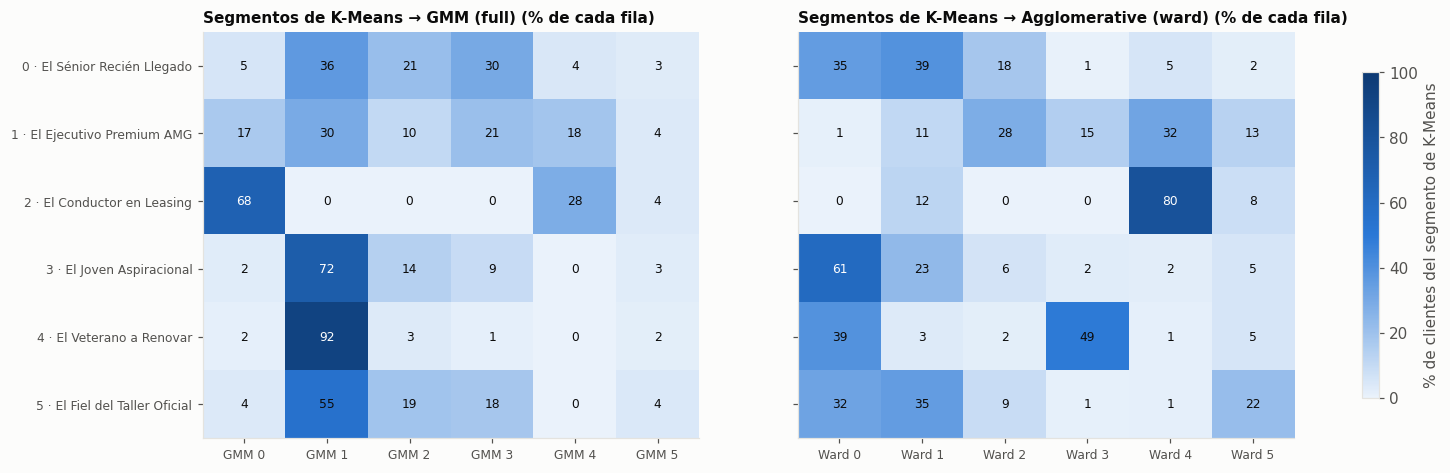

In [10]:
# Nombres de negocio de los segmentos de K-Means (cuaderno 04), si están disponibles
fichero_04 = DATA_DIR / "clientes_segmentos_k6.csv"
if fichero_04.exists():
    seg = pd.read_csv(fichero_04, usecols=["cluster", "segmento"]).drop_duplicates().set_index("cluster")["segmento"]
    nombres_km = {c: f"{c} · {seg[c]}" for c in range(K)}
else:
    nombres_km = {c: f"Clúster {c}" for c in range(K)}

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, alt in zip(axes, ["GMM (full)", "Agglomerative (ward)"]):
    ct = pd.crosstab(pd.Series(ref).map(nombres_km), etiquetas[alt], normalize="index") * 100
    ct = ct.reindex([nombres_km[c] for c in range(K)])
    im = ax.imshow(ct.values, cmap=ps.SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
    corto = {"GMM (full)": "GMM", "Agglomerative (ward)": "Ward"}[alt]
    ax.set_xticks(range(ct.shape[1]), [f"{corto} {c}" for c in ct.columns], fontsize=8)
    ax.set_yticks(range(ct.shape[0]), ct.index if ax is axes[0] else [""] * len(ct), fontsize=8); ax.grid(False)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            v = ct.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else ps.INK)
    ax.set_title(f"Segmentos de K-Means → {alt} (% de cada fila)", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="% de clientes del segmento de K-Means")
fig.savefig(FIG_DIR / "A1_contingencia.png", bbox_inches="tight"); plt.show()

**Sí, los segmentos cambian de forma significativa.** Los índices de coincidencia con K-Means son bajos (ARI muy lejos de 1) y en la tabla de
contingencia los clientes de casi todos los segmentos de K-Means se reparten entre varios grupos de los otros algoritmos:

- El **GMM** reorganiza a los clientes según su financiación y su motorización (sección 3), así que mezcla perfiles muy distintos (por ejemplo,
  todos los que nunca han financiado quedan juntos aunque tengan edades, antigüedades y usos del taller muy diferentes).
- **Ward** se parece algo más a K-Means (busca también grupos compactos), pero trazando fronteras distintas: con clientes que forman un continuo,
  pequeños cambios en el criterio de unión desplazan los límites entre segmentos.
- La excepción es el **Conductor en Leasing**, que se mantiene bastante reconocible en ambos algoritmos (la mayoría de sus clientes caen en un
  mismo grupo) porque se define por una variable muy marcada: la financiación activa.
- El **K-Means entrenado con la muestra** coincide mucho más con el K-Means completo que cualquier otro algoritmo, lo que indica que los segmentos
  de K-Means son consistentes (este punto se estudia a fondo en el reto avanzado 3, de estabilidad).

## 8. Conclusión: ¿qué algoritmo es el más adecuado?

**K-Means es el algoritmo más adecuado para esta segmentación**, por cinco motivos:

1. **Mejor calidad de los grupos.** Tiene la mejor silueta y el mejor Calinski-Harabasz de todos los algoritmos comparados con k = 6.
   En Davies-Bouldin solo le supera Agglomerative con `average`, pero es un espejismo: ese índice premia que los grupos estén lejos unos de
   otros, y `average` crea cinco grupos diminutos de clientes extremos, muy alejados del resto, mientras deja al 97 % de los clientes en un
   único grupo. Entre las segmentaciones utilizables, K-Means es también la mejor en Davies-Bouldin.
2. **Segmentos equilibrados y utilizables.** Sus seis grupos tienen entre el 12 % y el 19 % de los clientes. El GMM concentra casi la mitad de los
   clientes en un solo grupo y Agglomerative con `average` mete a casi todos en uno.
3. **Coherente con nuestros datos.** El GMM supone variables continuas y gaussianas y se desvía hacia las columnas 0/1; K-Means trabaja con
   distancias y aprovecha todas las variables a la vez.
4. **Escalable.** Se entrena con los 173.456 clientes en segundos. Agglomerative no cabe en memoria con todos los clientes y obliga a usar una
   muestra; DBSCAN ni siquiera permite fijar el número de segmentos.
5. **Interpretable y reproducible.** Cada segmento tiene un centro que resume a su cliente tipo (base de las fichas del cuaderno 04), y con una
   semilla fija el resultado es siempre el mismo.

**Matiz importante.** Todas las siluetas son bajas, también la de K-Means: los clientes forman un continuo y ningún algoritmo encuentra grupos
nítidamente separados. Por eso los segmentos de K-Means deben entenderse como **perfiles tipo útiles para orientar acciones**, no como grupos
aislados. Si en el futuro se quisiera aprovechar un modelo probabilístico como el GMM, habría que entrenarlo solo con las variables continuas o
con un modelo pensado para datos mixtos.